# Reaction time and prior-choice congruency

This is the complete analysis for the RT-only project.

**Question:** At 0%, 6.25%, and 12.5% visual contrast, do mice begin prior-congruent choices earlier than prior-incongruent choices?

Reaction time is measured from stimulus onset to first detected movement:

$$RT = t_{first\ movement} - t_{stimulus\ onset}$$

The displayed difference is always:

$$\Delta RT = RT_{incongruent} - RT_{congruent}$$

A positive difference supports the hypothesis that prior-congruent choices begin earlier.

The notebook progresses from one session, to every session of one mouse, to every mouse in the 459-session Brain-Wide Map release. It uses all completed choices. A disabled `CORRECT_ONLY` switch is retained for a future correct-trial sensitivity analysis.

## 1. Configuration

Install the environment once from the project root with `python -m pip install -r requirements.txt`. The first full data refresh requires internet access; later runs load the compact processed file.

In [1]:
from __future__ import annotations

import json
import os
import re
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"
CACHE_DIR = DATA_DIR / "cache"
RESULTS_DIR = PROJECT_ROOT / "results"
PROCESSED_PATH = DATA_DIR / "reaction_time_trials.parquet"
STATUS_PATH = DATA_DIR / "download_status.csv"

PROTOTYPE_MOUSE = "CSH_ZAD_029"
PROTOTYPE_SESSION = "fcd49e34-f07b-441c-b2ac-cb8c462ec5ac"
CONTRASTS = (0.0, 0.0625, 0.125)
CONTRAST_LABELS = {0.0: "0%", 0.0625: "6.25%", 0.125: "12.5%"}
MAX_RT_SECONDS = 2.0
CORRECT_ONLY = False       # Future sensitivity analysis: change to True and rerun analysis cells.
REFRESH_DATA = False       # Change to True only when rebuilding from IBL source data.
RANDOM_SEED = 2026

COLORS = {"congruent": "#4f8cff", "incongruent": "#82b86b"}
DIFFERENCE_COLOR = "#8a63d2"

DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
print(f"Project root: {PROJECT_ROOT}")
print(f"Primary analysis: {'correct choices only' if CORRECT_ONLY else 'all completed choices'}")

Project root: /Users/default/Desktop/study/CompN/compneuro-course-content-main/team-tbd
Primary analysis: all completed choices


## 2. Download and validate the trial events

The BWM metadata define the 459-session release and trial coordinates. ONE supplies only the behavioral trial attributes needed for stimulus onset and first movement. BWM rows are attached to ONE rows only after an exact or unique ordered fingerprint match.

In [2]:
BWM_URL = (
    "https://ibl-brain-wide-map-public.s3.us-east-1.amazonaws.com/"
    "sample_data/Neuromatch/data_firstMove.zip"
)
ONE_BASE_URL = "https://openalyx.internationalbrainlab.org"
TRIAL_ATTRIBUTES = [
    "probabilityLeft", "contrastLeft", "contrastRight", "choice", "feedbackType",
    "stimOn_times", "firstMovement_times",
]
FINGERPRINT_COLUMNS = (
    "probabilityLeft", "contrastLeft", "contrastRight", "choice", "feedbackType",
    "block", "block_trial_number",
)


def fetch_bwm_metadata() -> tuple[Path, Path]:
    '''Return local BWM trials and sessions tables, downloading only those members if needed.'''
    legacy = PROJECT_ROOT / "data" / "raw" / "firstMove"
    if (legacy / "trials.pqt").exists() and (legacy / "sessions.pqt").exists():
        return legacy / "trials.pqt", legacy / "sessions.pqt"

    destination = CACHE_DIR / "bwm"
    trials_path = destination / "trials.pqt"
    sessions_path = destination / "sessions.pqt"
    if trials_path.exists() and sessions_path.exists():
        return trials_path, sessions_path

    from remotezip import RemoteZip

    destination.mkdir(parents=True, exist_ok=True)
    wanted = {"trials.pqt": trials_path, "sessions.pqt": sessions_path}
    with RemoteZip(BWM_URL) as archive:
        members = {Path(name).name: name for name in archive.namelist()}
        missing = sorted(set(wanted).difference(members))
        if missing:
            raise FileNotFoundError(f"BWM archive is missing: {missing}")
        for basename, output in wanted.items():
            if output.exists():
                continue
            with archive.open(members[basename]) as source, output.open("wb") as sink:
                shutil.copyfileobj(source, sink)
    return trials_path, sessions_path


def with_block_positions(trials: pd.DataFrame) -> pd.DataFrame:
    output = trials.copy()
    if {"block", "block_trial_number"}.issubset(output.columns):
        return output
    probability = pd.to_numeric(output["probabilityLeft"], errors="coerce")
    block = probability.ne(probability.shift()).cumsum().sub(1).astype(int)
    output["block"] = block
    output["block_trial_number"] = output.groupby(block, sort=False).cumcount()
    return output


def fingerprints(trials: pd.DataFrame) -> list[tuple[float | None, ...]]:
    frame = with_block_positions(trials)
    missing = sorted(set(FINGERPRINT_COLUMNS).difference(frame.columns))
    if missing:
        raise ValueError(f"Cannot fingerprint trials; missing: {missing}")
    numeric = frame[list(FINGERPRINT_COLUMNS)].apply(pd.to_numeric, errors="coerce")
    return [
        tuple(None if pd.isna(value) else round(float(value), 12) for value in row)
        for row in numeric.itertuples(index=False, name=None)
    ]


def match_ordered_trials(bwm_trials: pd.DataFrame, one_trials: pd.DataFrame) -> tuple[np.ndarray, str]:
    '''Return ONE row positions for an exact or uniquely embedded BWM sequence.'''
    target = fingerprints(bwm_trials)
    source = fingerprints(one_trials)
    if target == source:
        return np.arange(len(target), dtype=int), "exact"
    if len(target) > len(source):
        raise ValueError("BWM has more trials than ONE")

    leftmost = []
    j = 0
    for item in target:
        while j < len(source) and source[j] != item:
            j += 1
        if j == len(source):
            raise ValueError("No monotonic BWM-to-ONE alignment exists")
        leftmost.append(j)
        j += 1

    rightmost = []
    j = len(source) - 1
    for item in reversed(target):
        while j >= 0 and source[j] != item:
            j -= 1
        if j < 0:
            raise ValueError("No monotonic BWM-to-ONE alignment exists")
        rightmost.append(j)
        j -= 1
    rightmost.reverse()

    if leftmost != rightmost:
        raise ValueError("BWM-to-ONE alignment is ambiguous")
    return np.asarray(leftmost, dtype=int), "unique_subsequence"


def cached_one_table(session: pd.Series) -> Path | None:
    '''Reuse a legacy table during this rebuild when it is already available.'''
    legacy_root = PROJECT_ROOT / "data" / "raw" / "one"
    root = (
        legacy_root / str(session["lab"]) / "Subjects" / str(session["subject"])
        / str(session["date"]) / f"{int(session['session_number']):03d}" / "alf"
    )
    paths = sorted(root.glob("**/_ibl_trials.table.pqt"))
    return paths[-1] if paths else None


def load_one_trials(one, eid: str, session: pd.Series) -> pd.DataFrame:
    cached = cached_one_table(session)
    if cached is not None:
        return pd.read_parquet(cached)
    trials = one.load_dataset(
        eid,
        "_ibl_trials.table.pqt",
        collection="alf",
        query_type="local",
    )
    if isinstance(trials, pd.DataFrame):
        return trials.reset_index(drop=True)
    if isinstance(trials, (str, Path)):
        return pd.read_parquet(trials).reset_index(drop=True)
    raise TypeError(f"Unexpected ONE trials table type: {type(trials).__name__}")


def label_selected_trials(frame: pd.DataFrame, session: pd.Series, match_method: str) -> pd.DataFrame:
    output = frame.copy().reset_index(drop=True)
    left = pd.to_numeric(output["contrastLeft"], errors="coerce")
    right = pd.to_numeric(output["contrastRight"], errors="coerce")
    probability = pd.to_numeric(output["probabilityLeft"], errors="coerce")
    choice = pd.to_numeric(output["choice"], errors="coerce")

    has_contrast = left.notna() | right.notna()
    output["contrast"] = (left.fillna(0) - right.fillna(0)).abs()
    output.loc[~has_contrast, "contrast"] = np.nan
    output["contrast_label"] = output["contrast"].map(CONTRAST_LABELS)

    prior_side = pd.Series(pd.NA, index=output.index, dtype="string")
    prior_side.loc[probability.eq(0.8)] = "left"
    prior_side.loc[probability.eq(0.2)] = "right"
    output["prior_side"] = prior_side

    choice_side = pd.Series(pd.NA, index=output.index, dtype="string")
    choice_side.loc[choice.eq(1)] = "left"
    choice_side.loc[choice.eq(-1)] = "right"
    output["choice_side"] = choice_side

    stimulus_side = pd.Series(pd.NA, index=output.index, dtype="string")
    stimulus_side.loc[left.fillna(0).gt(right.fillna(0))] = "left"
    stimulus_side.loc[right.fillna(0).gt(left.fillna(0))] = "right"
    output["stimulus_side"] = stimulus_side

    output["congruency"] = pd.Series(pd.NA, index=output.index, dtype="string")
    usable = output["prior_side"].notna() & output["choice_side"].notna()
    output.loc[usable & output["prior_side"].eq(output["choice_side"]), "congruency"] = "congruent"
    output.loc[usable & output["prior_side"].ne(output["choice_side"]), "congruency"] = "incongruent"
    output["correct"] = pd.to_numeric(output["feedbackType"], errors="coerce").eq(1)

    output["reaction_time_s"] = output["firstMovement_times"] - output["stimOn_times"]
    output["reaction_time_ms"] = 1000.0 * output["reaction_time_s"]
    output["valid_rt"] = (
        np.isfinite(output["reaction_time_s"])
        & output["reaction_time_s"].gt(0)
        & output["reaction_time_s"].le(MAX_RT_SECONDS)
    )

    selected = (
        output["contrast_label"].notna()
        & output["prior_side"].notna()
        & output["choice_side"].notna()
        & output["congruency"].notna()
    )
    output = output.loc[selected].copy()
    output["subject"] = str(session["subject"])
    output["lab"] = str(session["lab"])
    output["date"] = str(session["date"])
    output["session_number"] = int(session["session_number"])
    output["match_method"] = match_method
    return output


def build_reaction_time_dataset() -> pd.DataFrame:
    trials_path, sessions_path = fetch_bwm_metadata()
    bwm = pd.read_parquet(trials_path).assign(eid=lambda x: x["eid"].astype(str))
    sessions = (
        pd.read_parquet(sessions_path)
        .assign(eid=lambda x: x["eid"].astype(str))
        .drop_duplicates("eid")
        .sort_values(["subject", "date", "session_number", "eid"])
        .reset_index(drop=True)
    )
    assert bwm["eid"].nunique() == 459, "Expected the fixed 459-session BWM release"
    assert sessions["subject"].nunique() == 139, "Expected 139 BWM mice"

    from one.api import ONE

    os.environ.setdefault("ONE_HTTP_DL_THREADS", "1")
    one_cache = CACHE_DIR / "one"
    one_cache.mkdir(parents=True, exist_ok=True)
    one = ONE(base_url=ONE_BASE_URL, password="international", silent=True, cache_dir=one_cache)
    # Load the public release index once so 459 dataset lookups stay local.
    one.load_cache(tag="Brainwidemap")
    checkpoint_root = CACHE_DIR / "sessions"
    checkpoint_root.mkdir(parents=True, exist_ok=True)

    statuses = []
    for index, session in sessions.iterrows():
        eid = str(session["eid"])
        checkpoint = checkpoint_root / f"{eid}.parquet"
        print(f"[{index + 1:03d}/459] {session['subject']} {eid}", flush=True)
        try:
            if checkpoint.exists():
                selected = pd.read_parquet(checkpoint)
                method = str(selected["match_method"].iloc[0]) if len(selected) else "reused"
            else:
                bwm_session = bwm.loc[bwm["eid"].eq(eid)].reset_index(drop=True)
                if bwm_session.empty:
                    raise ValueError("BWM contains no trials for this session")
                one_trials = load_one_trials(one, eid, session)
                positions, method = match_ordered_trials(bwm_session, one_trials)
                attached = bwm_session.copy()
                source = one_trials.iloc[positions].reset_index(drop=True)
                attached["stimOn_times"] = pd.to_numeric(source["stimOn_times"], errors="coerce").to_numpy()
                attached["firstMovement_times"] = pd.to_numeric(source["firstMovement_times"], errors="coerce").to_numpy()
                attached["one_trial_position"] = positions
                selected = label_selected_trials(attached, session, method)
                selected.to_parquet(checkpoint, index=False)
            statuses.append({
                "eid": eid, "subject": str(session["subject"]), "completed": True,
                "match_method": method, "selected_rows": len(selected),
                "invalid_rt_rows": int((~selected["valid_rt"]).sum()), "reason": "",
            })
        except Exception as error:
            statuses.append({
                "eid": eid, "subject": str(session["subject"]), "completed": False,
                "match_method": "", "selected_rows": 0, "invalid_rt_rows": 0,
                "reason": f"{type(error).__name__}: {error}",
            })
            print(f"  FAILED: {error}", flush=True)
        pd.DataFrame(statuses).to_csv(STATUS_PATH, index=False)

    status = pd.DataFrame(statuses)
    failures = status.loc[~status["completed"]]
    if not failures.empty:
        display(failures)
        raise RuntimeError(f"{len(failures)} sessions failed; rerun to resume before analysis")

    frames = [pd.read_parquet(checkpoint_root / f"{eid}.parquet") for eid in sessions["eid"]]
    output = pd.concat(frames, ignore_index=True)
    preferred = [
        "eid", "subject", "lab", "date", "session_number", "psth_index",
        "one_trial_position", "block", "block_trial_number", "probabilityLeft",
        "prior_side", "contrastLeft", "contrastRight", "contrast", "contrast_label",
        "stimulus_side", "choice", "choice_side", "feedbackType", "correct", "congruency",
        "stimOn_times", "firstMovement_times", "reaction_time_s", "reaction_time_ms",
        "valid_rt", "match_method",
    ]
    output = output[preferred].sort_values(["subject", "date", "session_number", "psth_index"])
    output.to_parquet(PROCESSED_PATH, index=False)
    return output.reset_index(drop=True)


if REFRESH_DATA or not PROCESSED_PATH.exists():
    trials = build_reaction_time_dataset()
else:
    trials = pd.read_parquet(PROCESSED_PATH)

print(f"Processed rows: {len(trials):,}")
print(f"Sessions: {trials['eid'].nunique()} | Mice: {trials['subject'].nunique()}")
display(pd.read_csv(STATUS_PATH).head())

Processed rows: 89,931
Sessions: 459 | Mice: 139


,eid,subject,completed,match_method,selected_rows,invalid_rt_rows,reason
0,034e726f-b35f-41e0-8d6c-a22cc32391fb,CSHL045,True,unique_subsequence,204,0,NaN
1,dfd8e7df-dc51-4589-b6ca-7baccfeb94b4,CSHL045,True,unique_subsequence,155,0,NaN
2,fa704052-147e-46f6-b190-a65b837e605e,CSHL045,True,unique_subsequence,393,0,NaN
3,46794e05-3f6a-4d35-afb3-9165091a5a74,CSHL045,True,unique_subsequence,260,0,NaN
4,7939711b-8b4d-4251-b698-b97c1eaa846e,CSHL045,True,unique_subsequence,296,0,NaN


## 3. Data checks and hierarchical summaries

RT distributions are skewed, so the project uses condition medians within each session. Sessions are weighted equally within a mouse, and mice are weighted equally in the final display. Raw trials are never pooled across mice for the group comparison.

In [3]:
# Validate the saved data before making any graph.
assert trials["eid"].nunique() == 459
assert trials["subject"].nunique() == 139
assert set(np.round(trials["contrast"].unique(), 4)) == set(CONTRASTS)
assert trials["prior_side"].isin(["left", "right"]).all()
assert trials["choice_side"].isin(["left", "right"]).all()
assert trials["congruency"].isin(["congruent", "incongruent"]).all()
assert np.allclose(
    trials["reaction_time_s"],
    trials["firstMovement_times"] - trials["stimOn_times"],
    equal_nan=True,
)
assert PROTOTYPE_SESSION in set(trials["eid"])
assert trials.loc[trials["subject"].eq(PROTOTYPE_MOUSE), "eid"].nunique() == 7

analysis = trials.loc[trials["valid_rt"]].copy()
if CORRECT_ONLY:
    analysis = analysis.loc[analysis["correct"]].copy()

coverage = analysis.groupby(["eid", "contrast_label"])["congruency"].nunique()
assert coverage.eq(2).all(), "Every session/contrast must retain both congruency conditions"

condition = (
    analysis.groupby(["eid", "subject", "contrast", "contrast_label", "congruency"], observed=True)
    ["reaction_time_ms"].agg([("n_trials", "size"), ("median_rt_ms", "median")]).reset_index()
)
session_summary = condition.pivot(
    index=["eid", "subject", "contrast", "contrast_label"],
    columns="congruency",
    values=["n_trials", "median_rt_ms"],
).reset_index()
session_summary.columns = [
    "_".join(str(part) for part in col if str(part)) if isinstance(col, tuple) else col
    for col in session_summary.columns
]
session_summary = session_summary.rename(columns={
    "n_trials_congruent": "congruent_n",
    "n_trials_incongruent": "incongruent_n",
    "median_rt_ms_congruent": "congruent_median_rt_ms",
    "median_rt_ms_incongruent": "incongruent_median_rt_ms",
})
session_summary["difference_ms"] = (
    session_summary["incongruent_median_rt_ms"] - session_summary["congruent_median_rt_ms"]
)

mouse_summary = (
    session_summary.groupby(["subject", "contrast", "contrast_label"], observed=True)
    .agg(
        n_sessions=("eid", "nunique"),
        congruent_rt_ms=("congruent_median_rt_ms", "mean"),
        incongruent_rt_ms=("incongruent_median_rt_ms", "mean"),
        difference_ms=("difference_ms", "mean"),
    )
    .reset_index()
)

assert session_summary["eid"].nunique() == 459
assert mouse_summary["subject"].nunique() == 139
print(f"Valid RT rows: {len(analysis):,}; excluded invalid/outlier rows: {(~trials['valid_rt']).sum():,}")
display(session_summary.head())

Valid RT rows: 89,871; excluded invalid/outlier rows: 60


,eid,subject,contrast,contrast_label,congruent_n,incongruent_n,congruent_median_rt_ms,incongruent_median_rt_ms,difference_ms
0,004d8fd5-41e7-4f1b-a45b-0d4ad76fe446,MFD_05,0.0000,0%,10.0,3.0,100.618918,84.997599,-15.621318
1,004d8fd5-41e7-4f1b-a45b-0d4ad76fe446,MFD_05,0.0625,6.25%,21.0,16.0,104.593285,119.402894,14.809609
2,004d8fd5-41e7-4f1b-a45b-0d4ad76fe446,MFD_05,0.1250,12.5%,15.0,10.0,107.650041,132.285394,24.635353
3,02fbb6da-3034-47d6-a61b-7d06c796a830,DY_010,0.0000,0%,25.0,7.0,133.307399,134.102079,0.794680
4,02fbb6da-3034-47d6-a61b-7d06c796a830,DY_010,0.0625,6.25%,63.0,28.0,139.052098,140.071423,1.019325


## 4. One mouse, one session

The prototype session belongs to `CSH_ZAD_029` and contains both conditions at all three contrasts. The upper row shows trial distributions and medians. The lower row shows the direct median difference.

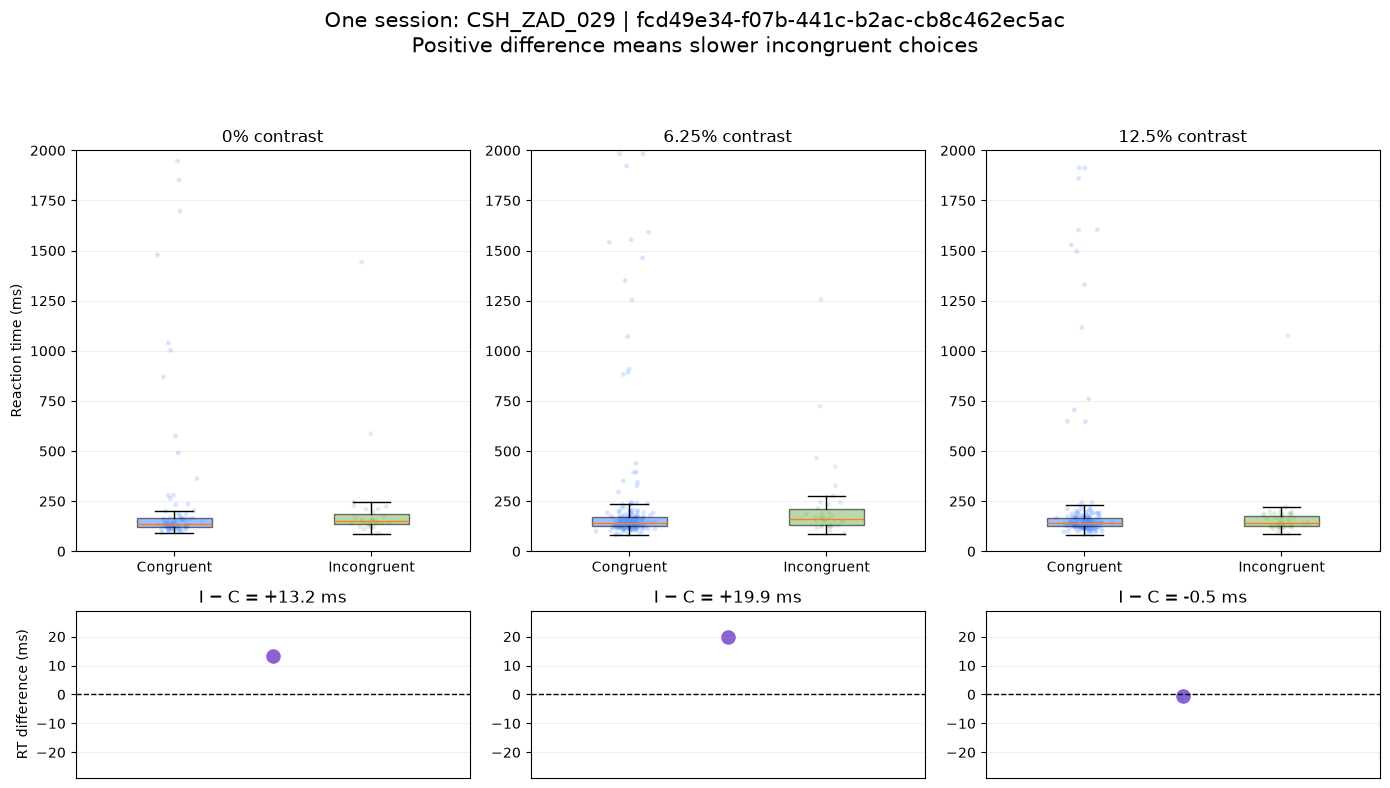

,contrast,contrast_label,congruency,n_trials,median_rt_ms
0,0.0000,0%,congruent,87,135.737348
1,0.0000,0%,incongruent,31,148.933381
2,0.0625,6.25%,congruent,210,142.543794
3,0.0625,6.25%,incongruent,38,162.452070
4,0.1250,12.5%,congruent,192,141.102577
5,0.1250,12.5%,incongruent,47,140.600511


In [4]:
def save_single_session_figure(frame: pd.DataFrame, eid: str, output: Path) -> pd.DataFrame:
    selected = frame.loc[frame["eid"].eq(eid)].copy()
    if selected.empty:
        raise ValueError(f"No trials for {eid}")
    summary = (
        selected.groupby(["contrast", "contrast_label", "congruency"], observed=True)["reaction_time_ms"]
        .agg([("n_trials", "size"), ("median_rt_ms", "median")]).reset_index()
    )
    pivot = summary.pivot(index=["contrast", "contrast_label"], columns="congruency", values="median_rt_ms").reset_index()
    pivot["difference_ms"] = pivot["incongruent"] - pivot["congruent"]

    fig, axes = plt.subplots(2, 3, figsize=(14, 8), gridspec_kw={"height_ratios": [2.4, 1]})
    rng = np.random.default_rng(RANDOM_SEED)
    ymax = min(MAX_RT_SECONDS * 1000, float(selected["reaction_time_ms"].quantile(0.99) * 1.08))
    diff_limit = max(20.0, float(np.abs(pivot["difference_ms"]).max() * 1.45))
    for column, contrast in enumerate(CONTRASTS):
        label = CONTRAST_LABELS[contrast]
        top = axes[0, column]
        contrast_frame = selected.loc[np.isclose(selected["contrast"], contrast)]
        values = []
        for x, condition_name in enumerate(("congruent", "incongruent")):
            y = contrast_frame.loc[contrast_frame["congruency"].eq(condition_name), "reaction_time_ms"].to_numpy()
            values.append(y)
            jitter = rng.normal(x, 0.045, size=len(y))
            top.scatter(jitter, y, s=12, alpha=0.22, color=COLORS[condition_name], edgecolors="none")
        box = top.boxplot(values, positions=[0, 1], widths=0.38, showfliers=False, patch_artist=True)
        for patch, condition_name in zip(box["boxes"], ("congruent", "incongruent")):
            patch.set_facecolor(COLORS[condition_name]); patch.set_alpha(0.55)
        top.set(xticks=[0, 1], xticklabels=["Congruent", "Incongruent"], title=f"{label} contrast", ylim=(0, ymax))
        if column == 0:
            top.set_ylabel("Reaction time (ms)")
        top.grid(axis="y", alpha=0.18)

        bottom = axes[1, column]
        difference = float(pivot.loc[np.isclose(pivot["contrast"], contrast), "difference_ms"].iloc[0])
        bottom.axhline(0, color="black", linestyle="--", linewidth=1)
        bottom.scatter([0], [difference], s=90, color=DIFFERENCE_COLOR)
        bottom.set(xlim=(-0.6, 0.6), ylim=(-diff_limit, diff_limit), xticks=[], title=f"I − C = {difference:+.1f} ms")
        if column == 0:
            bottom.set_ylabel("RT difference (ms)")
        bottom.grid(axis="y", alpha=0.18)
    fig.suptitle(f"One session: {selected['subject'].iloc[0]} | {eid}\nPositive difference means slower incongruent choices", fontsize=15)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    output.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output, dpi=180, bbox_inches="tight")
    plt.show()
    return summary


single_dir = RESULTS_DIR / "01_single_session"
single_summary = save_single_session_figure(analysis, PROTOTYPE_SESSION, single_dir / "reaction_time.png")
single_summary.to_csv(single_dir / "summary.csv", index=False)
display(single_summary)

## 5. All sessions of one mouse, then every mouse

Each mouse figure has one column per contrast. The upper row pairs congruent and incongruent session medians; the lower row shows each session's direct difference. The prototype mouse is displayed first, then the same figure is saved for all 139 mice.

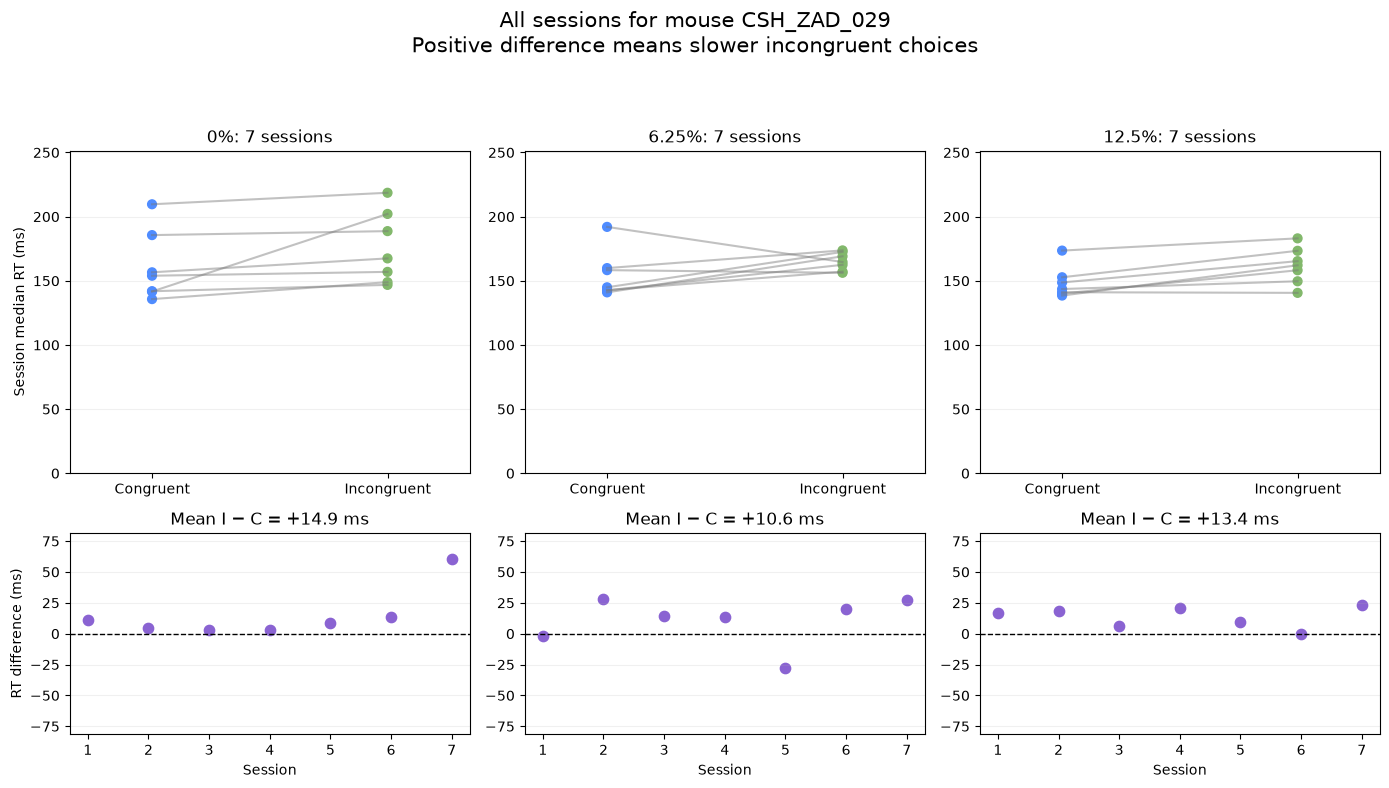

Saved 139 mouse figures to /Users/default/Desktop/study/CompN/compneuro-course-content-main/team-tbd/results/02_each_mouse


,subject,contrast,contrast_label,n_sessions,congruent_rt_ms,incongruent_rt_ms,difference_ms
54,CSH_ZAD_029,0.0000,0%,7,160.721351,175.656159,14.934808
55,CSH_ZAD_029,0.0625,6.25%,7,154.481041,165.114117,10.633076
56,CSH_ZAD_029,0.1250,12.5%,7,148.316033,161.756421,13.440388


In [5]:
def safe_name(value: str) -> str:
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", value)


def save_mouse_figure(summary: pd.DataFrame, subject: str, output: Path, *, show: bool = False) -> None:
    selected = summary.loc[summary["subject"].eq(subject)].sort_values(["contrast", "eid"])
    fig, axes = plt.subplots(2, 3, figsize=(14, 8), gridspec_kw={"height_ratios": [1.6, 1]})
    condition_values = selected[["congruent_median_rt_ms", "incongruent_median_rt_ms"]].to_numpy()
    ymax = min(MAX_RT_SECONDS * 1000, float(np.nanmax(condition_values) * 1.15))
    diff_limit = max(20.0, float(np.abs(selected["difference_ms"]).max() * 1.35))
    for column, contrast in enumerate(CONTRASTS):
        label = CONTRAST_LABELS[contrast]
        current = selected.loc[np.isclose(selected["contrast"], contrast)].reset_index(drop=True)
        top = axes[0, column]
        for _, row in current.iterrows():
            top.plot([0, 1], [row["congruent_median_rt_ms"], row["incongruent_median_rt_ms"]], color="#777777", alpha=0.45)
            top.scatter([0, 1], [row["congruent_median_rt_ms"], row["incongruent_median_rt_ms"]], s=40, color=[COLORS["congruent"], COLORS["incongruent"]])
        top.set(xticks=[0, 1], xticklabels=["Congruent", "Incongruent"], xlim=(-0.35, 1.35), ylim=(0, ymax), title=f"{label}: {len(current)} sessions")
        if column == 0:
            top.set_ylabel("Session median RT (ms)")
        top.grid(axis="y", alpha=0.18)

        bottom = axes[1, column]
        x = np.arange(len(current))
        bottom.axhline(0, color="black", linestyle="--", linewidth=1)
        bottom.scatter(x, current["difference_ms"], s=55, color=DIFFERENCE_COLOR)
        bottom.set(xticks=x, xticklabels=[str(i + 1) for i in x], ylim=(-diff_limit, diff_limit), xlabel="Session", title=f"Mean I − C = {current['difference_ms'].mean():+.1f} ms")
        if column == 0:
            bottom.set_ylabel("RT difference (ms)")
        bottom.grid(axis="y", alpha=0.18)
    fig.suptitle(f"All sessions for mouse {subject}\nPositive difference means slower incongruent choices", fontsize=15)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    output.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output, dpi=160, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)


mouse_dir = RESULTS_DIR / "02_each_mouse"
mouse_dir.mkdir(parents=True, exist_ok=True)
session_summary.to_csv(mouse_dir / "session_summary.csv", index=False)
mouse_summary.to_csv(mouse_dir / "mouse_summary.csv", index=False)

save_mouse_figure(session_summary, PROTOTYPE_MOUSE, mouse_dir / f"{safe_name(PROTOTYPE_MOUSE)}.png", show=True)
for subject in sorted(session_summary["subject"].unique()):
    if subject == PROTOTYPE_MOUSE:
        continue
    save_mouse_figure(session_summary, subject, mouse_dir / f"{safe_name(subject)}.png")

mouse_figures = sorted(mouse_dir.glob("*.png"))
assert len(mouse_figures) == 139
print(f"Saved {len(mouse_figures)} mouse figures to {mouse_dir}")
display(mouse_summary.loc[mouse_summary["subject"].eq(PROTOTYPE_MOUSE)])

## 6. All mice and all sessions

Each point is one equally weighted mouse after first averaging its session medians. The final difference panels make the hypothesis direction visible without treating thousands of trials as independent observations.

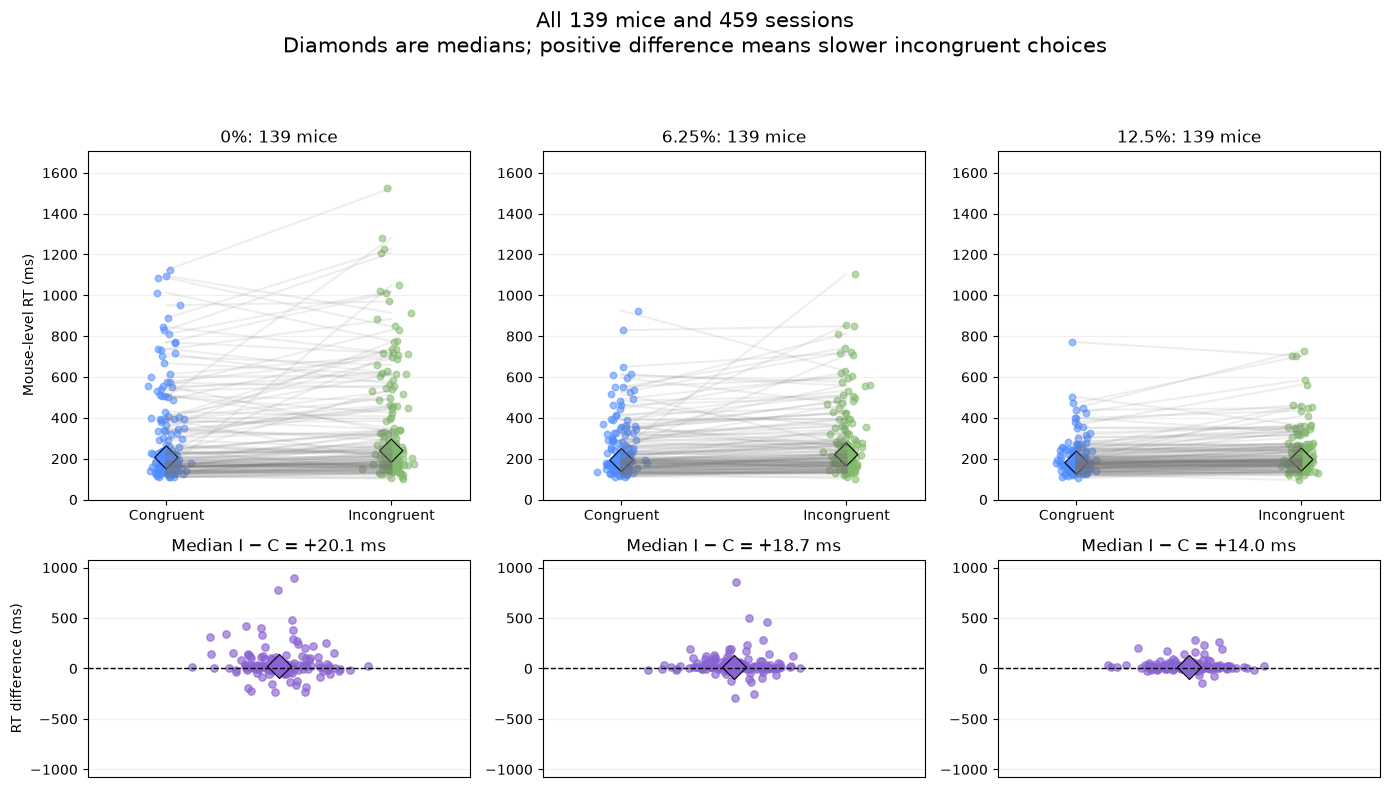

,contrast,n_mice,median_congruent_rt_ms,median_incongruent_rt_ms,median_difference_ms,mean_difference_ms,mice_with_positive_difference,proportion_positive
0,0%,139,206.161699,239.230557,20.112558,52.609088,95,0.683453
1,6.25%,139,193.118654,220.551967,18.677853,38.527047,103,0.741007
2,12.5%,139,180.653931,195.762933,13.976272,27.152413,111,0.798561


In [6]:
def save_all_mice_figure(summary: pd.DataFrame, output: Path) -> pd.DataFrame:
    fig, axes = plt.subplots(2, 3, figsize=(14, 8), gridspec_kw={"height_ratios": [1.6, 1]})
    rng = np.random.default_rng(RANDOM_SEED)
    ymax = min(MAX_RT_SECONDS * 1000, float(summary[["congruent_rt_ms", "incongruent_rt_ms"]].to_numpy().max() * 1.12))
    diff_limit = max(20.0, float(np.abs(summary["difference_ms"]).max() * 1.2))
    rows = []
    for column, contrast in enumerate(CONTRASTS):
        label = CONTRAST_LABELS[contrast]
        current = summary.loc[np.isclose(summary["contrast"], contrast)].copy()
        top = axes[0, column]
        for _, row in current.iterrows():
            top.plot([0, 1], [row["congruent_rt_ms"], row["incongruent_rt_ms"]], color="#777777", alpha=0.12)
        top.scatter(np.zeros(len(current)) + rng.normal(0, 0.035, len(current)), current["congruent_rt_ms"], s=22, alpha=0.55, color=COLORS["congruent"])
        top.scatter(np.ones(len(current)) + rng.normal(0, 0.035, len(current)), current["incongruent_rt_ms"], s=22, alpha=0.55, color=COLORS["incongruent"])
        medians = [current["congruent_rt_ms"].median(), current["incongruent_rt_ms"].median()]
        top.scatter([0, 1], medians, s=140, marker="D", color=[COLORS["congruent"], COLORS["incongruent"]], edgecolor="black", linewidth=0.8)
        top.set(xticks=[0, 1], xticklabels=["Congruent", "Incongruent"], xlim=(-0.35, 1.35), ylim=(0, ymax), title=f"{label}: {len(current)} mice")
        if column == 0:
            top.set_ylabel("Mouse-level RT (ms)")
        top.grid(axis="y", alpha=0.18)

        bottom = axes[1, column]
        jitter = rng.normal(0, 0.055, len(current))
        bottom.axhline(0, color="black", linestyle="--", linewidth=1)
        bottom.scatter(jitter, current["difference_ms"], s=28, alpha=0.65, color=DIFFERENCE_COLOR)
        median_difference = float(current["difference_ms"].median())
        bottom.scatter([0], [median_difference], s=150, marker="D", color=DIFFERENCE_COLOR, edgecolor="black", linewidth=0.8)
        bottom.set(xlim=(-0.35, 0.35), ylim=(-diff_limit, diff_limit), xticks=[], title=f"Median I − C = {median_difference:+.1f} ms")
        if column == 0:
            bottom.set_ylabel("RT difference (ms)")
        bottom.grid(axis="y", alpha=0.18)
        rows.append({
            "contrast": label,
            "n_mice": len(current),
            "median_congruent_rt_ms": medians[0],
            "median_incongruent_rt_ms": medians[1],
            "median_difference_ms": median_difference,
            "mean_difference_ms": float(current["difference_ms"].mean()),
            "mice_with_positive_difference": int(current["difference_ms"].gt(0).sum()),
            "proportion_positive": float(current["difference_ms"].gt(0).mean()),
        })
    fig.suptitle("All 139 mice and 459 sessions\nDiamonds are medians; positive difference means slower incongruent choices", fontsize=15)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    output.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output, dpi=180, bbox_inches="tight")
    plt.show()
    return pd.DataFrame(rows)


all_dir = RESULTS_DIR / "03_all_mice"
all_summary = save_all_mice_figure(mouse_summary, all_dir / "reaction_time.png")
all_summary.to_csv(all_dir / "summary.csv", index=False)
display(all_summary)

## 7. Final checks

These checks make the saved result hierarchy part of the reproducible analysis. No formal p-values, confidence intervals, or mixed models are used in this graph-first version.

In [7]:
expected_files = [
    PROCESSED_PATH,
    STATUS_PATH,
    RESULTS_DIR / "01_single_session" / "reaction_time.png",
    RESULTS_DIR / "01_single_session" / "summary.csv",
    RESULTS_DIR / "02_each_mouse" / "session_summary.csv",
    RESULTS_DIR / "02_each_mouse" / "mouse_summary.csv",
    RESULTS_DIR / "03_all_mice" / "reaction_time.png",
    RESULTS_DIR / "03_all_mice" / "summary.csv",
]
for path in expected_files:
    assert path.exists() and path.stat().st_size > 0, f"Missing or empty output: {path}"
assert len(list((RESULTS_DIR / "02_each_mouse").glob("*.png"))) == 139
assert pd.read_csv(STATUS_PATH)["completed"].all()

print("RT-only analysis complete")
print(f"  {trials['eid'].nunique()} sessions")
print(f"  {trials['subject'].nunique()} mice")
print(f"  {len(analysis):,} valid RT trials")
print("  1 prototype-session figure")
print("  139 per-mouse figures")
print("  1 all-mice figure")

RT-only analysis complete
  459 sessions
  139 mice
  89,871 valid RT trials
  1 prototype-session figure
  139 per-mouse figures
  1 all-mice figure
